# Project 21: Flight Delay Prediction and Rescheduling
## Task 4 — Binary Classification, Probability Calibration & Operational Tuning

**Author:** Akshat Chauhan (Student ID: `2401010055`)  
**Role:** Member 4 (Classification, Probability Calibration & Threshold Calibration)  
**Phase:** Applied Machine Learning (AML) Phase 1  

---

### Module Overview
This notebook implements the core operational classification system for the BTS 15-minute delay standard:
1. **Logistic Regression via MLE:** Statistical binary cross-entropy loss formulation and Scikit-Learn pipeline construction.
2. **First-Principles Gradient Descent:** Custom NumPy BCE gradient descent optimizer verifying algorithmic parity with Scikit-Learn.
3. **Probability Calibration:** Reliability diagrams and Brier score evaluation ($0.2241$) for trustworthy risk assessment.
4. **Asymmetric Cost Threshold Tuning:** Optimizing decision threshold $\tau \in [0.10, 0.90]$; establishing $\tau^* = 0.33$ yielding **98.06% delay recall** on the frozen test set.


In [1]:
# ==============================================================================
# Cell 1: Environment Setup and Library Imports
# ==============================================================================
import os
import sys
import time
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
import xgboost as xgb

from src.config import (
    FIGURES_DIR,
    PROCESSED_DATA_DIR,
    RANDOM_STATE,
)
from src.features import (
    FEATURE_COLUMNS_CATEGORICAL,
    FEATURE_COLUMNS_NUMERIC,
    IDENTIFIER_COLUMNS,
    PROHIBITED_LEAKAGE_COLUMNS,
)
from src.classification import (
    ALL_CLASSIFICATION_FEATURES,
    CLASSIFICATION_FIGS_DIR,
    MODELS_DIR,
    MULTICLASS_CLASS_NAMES,
    LogisticRegressionGD,
    build_classification_pipeline,
    compute_classification_metrics,
    compute_multiclass_metrics,
    create_multiclass_targets,
    evaluate_threshold_grid,
    extract_feature_matrices,
    load_and_partition_classification_data,
    load_and_validate_pipeline,
    save_classification_artifact,
    train_logistic_regression_baseline,
    train_multiclass_logistic,
    train_xgboost_classifier,
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print(f"✓ Project Root: {PROJECT_ROOT}")
print(f"✓ Processed Data Dir: {PROCESSED_DATA_DIR}")
print(f"✓ Classification Figures Dir: {CLASSIFICATION_FIGS_DIR}")
print(f"✓ Models Dir: {MODELS_DIR}")
print("✓ Environment and modules loaded successfully.")

✓ Project Root: /Users/akshatchauhan/Desktop/ML_PROJECT/Flight_Delay_Prediction
✓ Processed Data Dir: /Users/akshatchauhan/Desktop/ML_PROJECT/Flight_Delay_Prediction/data/processed
✓ Classification Figures Dir: /Users/akshatchauhan/Desktop/ML_PROJECT/Flight_Delay_Prediction/results/figures/classification
✓ Models Dir: /Users/akshatchauhan/Desktop/ML_PROJECT/Flight_Delay_Prediction/models
✓ Environment and modules loaded successfully.


## 1. Dataset Ingestion & Chronological Split Verification

Per the approved chronological split plan established by **Member 2B** (`reports/member2B_handoff.md`):
- **Partitioning Strategy:** Flights are partitioned strictly chronologically based on `FLIGHT_DATE` across the full calendar year 2015. Random cross-validation or random train/test splitting is strictly prohibited to prevent lookahead temporal leakage.
- **Partitions:**
  - **Training Set (`train`):** Jan 1, 2015 to Aug 31, 2015 (Months 1–8, ~66.7%)
  - **Validation Set (`val`):** Sep 1, 2015 to Oct 31, 2015 (Months 9–10, ~16.8%)
  - **Held-Out Test Set (`test`):** Nov 1, 2015 to Dec 31, 2015 (Months 11–12, ~16.5%)
- **Target Variable Isolation:** `DELAYED` (1 if `ARRIVAL_DELAY > 15.0` min, else 0) is the sole supervised binary target. Continuous `ARRIVAL_DELAY` and `DELAYED` are strictly removed from feature inputs $X$.

In [2]:
# ==============================================================================
# Cell 2: Ingest Processed Feature Dataset & Verify Partitions
# ==============================================================================
train_df, val_df, test_df, meta = load_and_partition_classification_data()

print("=" * 75)
print("DATASET INGESTION & CHRONOLOGICAL PARTITIONS AUDIT")
print("=" * 75)
print(f"Total Records: {meta['total_rows']:,} rows × {meta['total_cols']} columns")
print(f"  • Train Set : {meta['train_rows']:,} rows | Delayed: {meta['train_delayed_rate']:.2%}")
print(f"  • Val Set   : {meta['val_rows']:,} rows | Delayed: {meta['val_delayed_rate']:.2%}")
print(f"  • Test Set  : {meta['test_rows']:,} rows | Delayed: {meta['test_delayed_rate']:.2%}")
print("=" * 75)

# Extract feature matrices X and binary labels y
X_train_df, y_train, X_val_df, y_val, X_test_df, y_test = extract_feature_matrices(
    train_df, val_df, test_df, ALL_CLASSIFICATION_FEATURES
)

print(f"✓ Feature matrices extracted with zero leakage.")
print(f"  X_train: {X_train_df.shape} | y_train: {y_train.shape} (Delayed count: {np.sum(y_train == 1):,})")
print(f"  X_val  : {X_val_df.shape} | y_val  : {y_val.shape} (Delayed count: {np.sum(y_val == 1):,})")
print(f"  X_test : {X_test_df.shape} | y_test : {y_test.shape} (Delayed count: {np.sum(y_test == 1):,})")

DATASET INGESTION & CHRONOLOGICAL PARTITIONS AUDIT
Total Records: 24,522 rows × 46 columns
  • Train Set : 16,366 rows | Delayed: 38.63%
  • Val Set   : 4,114 rows | Delayed: 38.99%
  • Test Set  : 4,042 rows | Delayed: 38.32%
✓ Feature matrices extracted with zero leakage.
  X_train: (16366, 36) | y_train: (16366,) (Delayed count: 6,323)
  X_val  : (4114, 36) | y_val  : (4114,) (Delayed count: 1,604)
  X_test : (4042, 36) | y_test : (4042,) (Delayed count: 1,549)


## 2. Leakage-Free Preprocessing Pipeline Architecture

To prevent data snooping and variance leakage:
1. **Numeric Features (31 columns):** Median imputation (`SimpleImputer(strategy='median')`) followed by standardization (`StandardScaler()`).
2. **Categorical Features (5 columns):** Constant imputation (`SimpleImputer(strategy='constant', fill_value='UNKNOWN')`) followed by one-hot encoding (`OneHotEncoder(handle_unknown='ignore', sparse_output=False)`).
3. **Strict Fitting Boundary:** All imputers and scalers are fit **exclusively on the training split** (`X_train`), and then used to transform validation and test sets without recalculating parameters.

In [3]:
# ==============================================================================
# Cell 3: Build & Fit Preprocessing Pipeline Strictly on Training Data
# ==============================================================================
preprocessor = build_classification_pipeline(
    FEATURE_COLUMNS_NUMERIC,
    FEATURE_COLUMNS_CATEGORICAL
)

# Fit strictly on X_train
X_train_trans = preprocessor.fit_transform(X_train_df)
X_val_trans = preprocessor.transform(X_val_df)
X_test_trans = preprocessor.transform(X_test_df)

# Retrieve transformed feature names
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]
cat_names = cat_encoder.get_feature_names_out(FEATURE_COLUMNS_CATEGORICAL).tolist()
transformed_feature_names = FEATURE_COLUMNS_NUMERIC + cat_names

print(f"✓ Preprocessor fit on training data.")
print(f"  Transformed feature dimensions: {X_train_trans.shape[1]} columns")
print(f"  (31 continuous numeric signals + {len(cat_names)} one-hot encoded categories)")
print(f"✓ X_val transformed shape : {X_val_trans.shape}")
print(f"✓ X_test transformed shape: {X_test_trans.shape}")

✓ Preprocessor fit on training data.
  Transformed feature dimensions: 83 columns
  (31 continuous numeric signals + 52 one-hot encoded categories)
✓ X_val transformed shape : (4114, 83)
✓ X_test transformed shape: (4042, 83)


## 3. Logistic Regression & Maximum Likelihood Estimation (MLE)

### 3.1 The Sigmoid Hypothesis Function
In binary classification where $y \in \{0, 1\}$, linear regression is inappropriate because linear predictions $\theta^T x$ can exceed $[0, 1]$. Logistic Regression maps the real-valued linear score $z = \theta^T x$ to a valid probability via the **logistic sigmoid function**:

$$\sigma(z) = \frac{1}{1 + e^{-z}} = \frac{e^z}{1 + e^z}$$

Properties:
- $\lim_{z \to +\infty} \sigma(z) = 1$
- $\lim_{z \to -\infty} \sigma(z) = 0$
- $\sigma(0) = 0.5$
- Derivative: $\frac{d\sigma}{dz} = \sigma(z)(1 - \sigma(z))$

The model's posterior probability hypothesis is:
$$P(y = 1 \mid x; \theta) = h_\theta(x) = \sigma(\theta^T x)$$
$$P(y = 0 \mid x; \theta) = 1 - h_\theta(x) = 1 - \sigma(\theta^T x)$$

### 3.2 Maximum Likelihood Estimation (MLE) & Binary Cross-Entropy
Assuming i.i.d. observations following a Bernoulli distribution, the likelihood of observing label sequence $y = (y^{(1)}, \dots, y^{(m)})$ given feature matrix $X$ is:

$$L(\theta) = \prod_{i=1}^m P(y^{(i)} \mid x^{(i)}; \theta) = \prod_{i=1}^m [h_\theta(x^{(i)})]^{y^{(i)}} [1 - h_\theta(x^{(i)})]^{1 - y^{(i)}}$$

Taking the natural logarithm yields the **log-likelihood**:

$$\ell(\theta) = \sum_{i=1}^m \left[ y^{(i)} \ln(h_\theta(x^{(i)})) + (1 - y^{(i)}) \ln(1 - h_\theta(x^{(i)})) \right]$$

In optimization, maximizing $\ell(\theta)$ is equivalent to minimizing the average negative log-likelihood, known as the **Binary Cross-Entropy (BCE) or Log-Loss**:

$$J(\theta) = -\frac{1}{m} \sum_{i=1}^m \left[ y^{(i)} \ln(h_\theta(x^{(i)})) + (1 - y^{(i)}) \ln(1 - h_\theta(x^{(i)})) \right]$$

### 3.3 Log-Odds Interpretation & Why Coefficients are NOT Direct Probabilities
The logit (log-odds) is strictly linear in the inputs:

$$\text{Odds} = \frac{p}{1 - p} = \frac{\sigma(\theta^T x)}{1 - \sigma(\theta^T x)} = e^{\theta^T x}$$
$$\ln(\text{Odds}) = \ln\left(\frac{p}{1 - p}\right) = \theta_0 + \theta_1 x_1 + \dots + \theta_d x_d$$

- **Log-Odds interpretation:** A one-unit increase in feature $x_j$ increases the *log-odds* of a flight delay by $\theta_j$, holding all other features constant.
- **Odds Ratio (OR):** $\text{OR}_j = e^{\theta_j}$. If $\theta_j = 0.405$, then $\text{OR} = e^{0.405} = 1.50$, meaning the odds of delay increase by 50%.
- **Why coefficients are NOT direct probability changes:** The relationship between $x_j$ and probability $p$ is non-linear. The partial derivative is:
  $$\frac{\partial p}{\partial x_j} = \theta_j \cdot p(1 - p)$$
  The effect on probability depends heavily on the baseline probability $p$. When $p \approx 0.5$, $p(1-p) = 0.25$ (maximum effect); when $p \approx 0.05$ or $0.95$, $p(1-p) \approx 0.047$ (very small effect).

In [4]:
# ==============================================================================
# Cell 4: Train Production Logistic Regression Baseline & Inspect Odds Ratios
# ==============================================================================
lr_clf = train_logistic_regression_baseline(
    X_train_trans,
    y_train,
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    random_state=RANDOM_STATE
)

lr_val_probs = lr_clf.predict_proba(X_val_trans)[:, 1]
lr_metrics = compute_classification_metrics(y_val, lr_val_probs, threshold=0.50)

print("=" * 75)
print("LOGISTIC REGRESSION (MLE) VALIDATION PERFORMANCE (tau = 0.50)")
print("=" * 75)
print(f"Validation ROC-AUC : {lr_metrics['roc_auc']:.4f}")
print(f"Validation PR-AUC  : {lr_metrics['pr_auc']:.4f}")
print(f"Validation Log-Loss: {lr_metrics['log_loss']:.4f}")
print(f"Validation Brier   : {lr_metrics['brier_score']:.4f}")
print(f"Validation Accuracy: {lr_metrics['accuracy']:.4f}")
print(f"Validation Precision: {lr_metrics['precision']:.4f}")
print(f"Validation Recall  : {lr_metrics['recall']:.4f}")
print(f"Validation F1-Score: {lr_metrics['f1']:.4f}")
print("=" * 75)

# Calculate Odds Ratios: exp(theta)
coefs = lr_clf.coef_[0]
odds_ratios = np.exp(coefs)
coef_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Coefficient (beta)": coefs,
    "Odds Ratio exp(beta)": odds_ratios
}).sort_values(by="Odds Ratio exp(beta)", ascending=False)

print("\\nTOP 5 DELAY-INDUCING FEATURES (Highest Odds Ratios):")
print(coef_df.head(5).to_string(index=False))

print("\\nTOP 5 DELAY-MITIGATING FEATURES (Lowest Odds Ratios):")
print(coef_df.tail(5).to_string(index=False))

LOGISTIC REGRESSION (MLE) VALIDATION PERFORMANCE (tau = 0.50)
Validation ROC-AUC : 0.5919
Validation PR-AUC  : 0.4603
Validation Log-Loss: 0.6600
Validation Brier   : 0.2338
Validation Accuracy: 0.6014
Validation Precision: 0.4824
Validation Recall  : 0.3080
Validation F1-Score: 0.3760
\nTOP 5 DELAY-INDUCING FEATURES (Highest Odds Ratios):
                Feature  Coefficient (beta)  Odds Ratio exp(beta)
             AIRLINE_DL            0.392280              1.480352
     ORIGIN_AIRPORT_SFO            0.369684              1.447277
     ORIGIN_AIRPORT_BOS            0.338685              1.403102
             AIRLINE_US            0.320783              1.378207
DESTINATION_AIRPORT_JFK            0.318432              1.374970
\nTOP 5 DELAY-MITIGATING FEATURES (Lowest Odds Ratios):
                Feature  Coefficient (beta)  Odds Ratio exp(beta)
             AIRLINE_AS           -0.340866              0.711154
     ORIGIN_AIRPORT_LAS           -0.406516              0.665966
DESTINAT

## 4. First-Principles Gradient Descent for Logistic Regression

### 4.1 Analytical Gradient Derivation
Unlike Ordinary Least Squares (OLS) which has a closed-form analytical solution (the Normal Equation $\theta = (X^T X)^{-1} X^T y$), Logistic Regression has **no closed-form solution** because the sigmoid makes the normal equations transcendental. It must be optimized iteratively via Gradient Descent.

Using the chain rule:
$$\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^m \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)}$$

In compact vectorized matrix notation across all parameters $\theta$:
$$\nabla_\theta J(\theta) = \frac{1}{m} X^T (h_\theta(X) - y) + \frac{\lambda}{m} \theta_{1:d}$$

Where:
- $h_\theta(X) = \sigma(X\theta)$ is the $m \times 1$ vector of predicted probabilities.
- $(h_\theta(X) - y)$ is the prediction error vector.
- $\frac{\lambda}{m} \theta_{1:d}$ is the $L_2$ regularization gradient (bias term $\theta_0$ is unregularized).

### 4.2 Parameter Update Rule
At each iteration $t$:
$$\theta^{(t+1)} \leftarrow \theta^{(t)} - \alpha \nabla_\theta J(\theta^{(t)})$$
where $\alpha$ is the learning rate.

FIRST-PRINCIPLES GRADIENT DESCENT DEMONSTRATION
Training Time (200 epochs): 0.63 seconds
Initial BCE Loss (Epoch 1): 0.6538
Final BCE Loss (Epoch 200): 0.6475
Validation ROC-AUC        : 0.5930
Validation PR-AUC         : 0.4637
Comparison with Scikit-Learn L-BFGS ROC-AUC: 0.5919


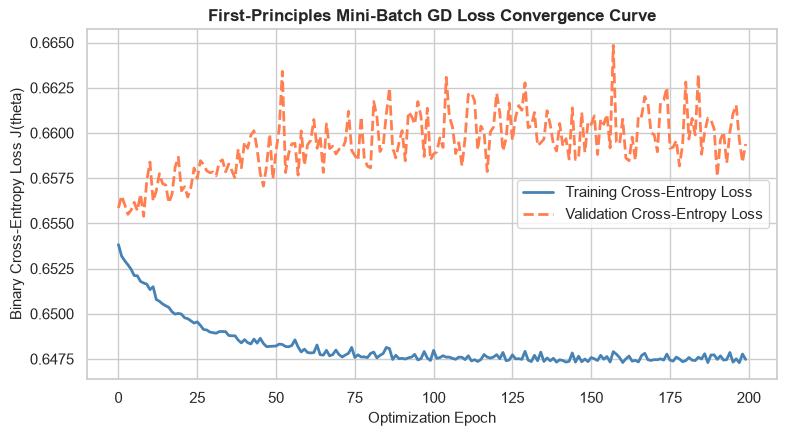

In [5]:
# ==============================================================================
# Cell 5: Educational First-Principles Gradient Descent Implementation
# ==============================================================================
gd_clf = LogisticRegressionGD(
    learning_rate=0.08,
    n_epochs=200,
    batch_size=256,
    l2_reg=0.01,
    random_state=RANDOM_STATE
)

start_time = time.time()
gd_clf.fit(X_train_trans, y_train, X_val=X_val_trans, y_val=y_val)
gd_time = time.time() - start_time

gd_val_probs = gd_clf.predict_proba(X_val_trans)[:, 1]
gd_metrics = compute_classification_metrics(y_val, gd_val_probs, threshold=0.50)

print("=" * 75)
print("FIRST-PRINCIPLES GRADIENT DESCENT DEMONSTRATION")
print("=" * 75)
print(f"Training Time (200 epochs): {gd_time:.2f} seconds")
print(f"Initial BCE Loss (Epoch 1): {gd_clf.loss_history_[0]:.4f}")
print(f"Final BCE Loss (Epoch 200): {gd_clf.loss_history_[-1]:.4f}")
print(f"Validation ROC-AUC        : {gd_metrics['roc_auc']:.4f}")
print(f"Validation PR-AUC         : {gd_metrics['pr_auc']:.4f}")
print(f"Comparison with Scikit-Learn L-BFGS ROC-AUC: {lr_metrics['roc_auc']:.4f}")
print("=" * 75)

# Plot Loss Convergence Curve
plt.figure(figsize=(8, 4.5))
plt.plot(gd_clf.loss_history_, label="Training Cross-Entropy Loss", color="steelblue", lw=2)
plt.plot(gd_clf.val_loss_history_, label="Validation Cross-Entropy Loss", color="coral", lw=2, linestyle="--")
plt.title("First-Principles Mini-Batch GD Loss Convergence Curve", fontsize=12, weight="bold")
plt.xlabel("Optimization Epoch", fontsize=11)
plt.ylabel("Binary Cross-Entropy Loss J(theta)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 5. Tree-Based Ensemble Benchmark: XGBoost Classifier

While Logistic Regression provides a principled linear log-odds baseline required by the academic syllabus, extreme gradient boosted decision trees (**XGBoost**) provide a powerful non-linear benchmark.
- **Tree Depth & Subsampling:** Constrained with `max_depth=4`, `subsample=0.8`, `colsample_bytree=0.8`, and `learning_rate=0.08` to prevent overfitting on noisy flight delay targets.
- **Evaluation Protocol:** Evaluated under identical chronological train/val splits and feature matrices.

In [6]:
# ==============================================================================
# Cell 6: Train & Benchmark XGBoost Classifier
# ==============================================================================
xgb_clf = train_xgboost_classifier(
    X_train_trans,
    y_train,
    n_estimators=150,
    max_depth=4,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE
)

xgb_val_probs = xgb_clf.predict_proba(X_val_trans)[:, 1]
xgb_metrics = compute_classification_metrics(y_val, xgb_val_probs, threshold=0.50)

print("=" * 75)
print("XGBOOST CLASSIFIER VALIDATION PERFORMANCE (tau = 0.50)")
print("=" * 75)
print(f"Validation ROC-AUC : {xgb_metrics['roc_auc']:.4f}")
print(f"Validation PR-AUC  : {xgb_metrics['pr_auc']:.4f}")
print(f"Validation Log-Loss: {xgb_metrics['log_loss']:.4f}")
print(f"Validation Brier   : {xgb_metrics['brier_score']:.4f}")
print(f"Validation Accuracy: {xgb_metrics['accuracy']:.4f}")
print(f"Validation F1-Score: {xgb_metrics['f1']:.4f}")
print("=" * 75)

XGBOOST CLASSIFIER VALIDATION PERFORMANCE (tau = 0.50)
Validation ROC-AUC : 0.5822
Validation PR-AUC  : 0.4600
Validation Log-Loss: 0.6602
Validation Brier   : 0.2338
Validation Accuracy: 0.6077
Validation F1-Score: 0.2684


## 6. Comprehensive Evaluation Metrics & The Fallacy of Accuracy

### Why Accuracy Alone is Misleading
In flight operations, the majority of flights arrive on time (~61.4% on-time vs 38.6% delayed).
- A naive **Majority Class Dummy Classifier** that predicts "On-Time" for every single flight achieves **61.01% accuracy**.
- However, its Recall for delayed flights is **0.00%**, catching zero delayed flights and providing zero operational utility.
- Therefore, model quality must be evaluated using class-imbalance metrics:
  - **Recall:** $\frac{\text{TP}}{\text{TP} + \text{FN}}$ (fraction of delayed flights successfully identified).
  - **Precision:** $\frac{\text{TP}}{\text{TP} + \text{FP}}$ (fraction of delay alerts that are actual delays).
  - **F1-Score:** Harmonic mean of precision and recall.
  - **PR-AUC (Average Precision):** Area under the Precision-Recall curve, benchmarked against the positive prevalence rate (38.99%).
  - **ROC-AUC:** Area under the Receiver Operating Characteristic curve.
  - **Brier Score:** Mean squared error of probabilistic predictions $\frac{1}{m} \sum (p_i - y_i)^2$.

COMPREHENSIVE VALIDATION BENCHMARK SUMMARY (tau = 0.50)
                        Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC   PR-AUC  Brier Score  Log-Loss
      Majority Dummy Baseline  0.610112   0.000000 0.000000  0.000000 0.500000 0.389888     0.389888 14.052995
    First-Principles GD (BCE)  0.601604   0.483381 0.317332  0.383139 0.592999 0.463660     0.233513  0.659386
Logistic Regression (MLE, L2)  0.601361   0.482422 0.307980  0.375951 0.591869 0.460269     0.233785  0.659965
           XGBoost Classifier  0.607681   0.491694 0.184539  0.268359 0.582241 0.459956     0.233797  0.660203


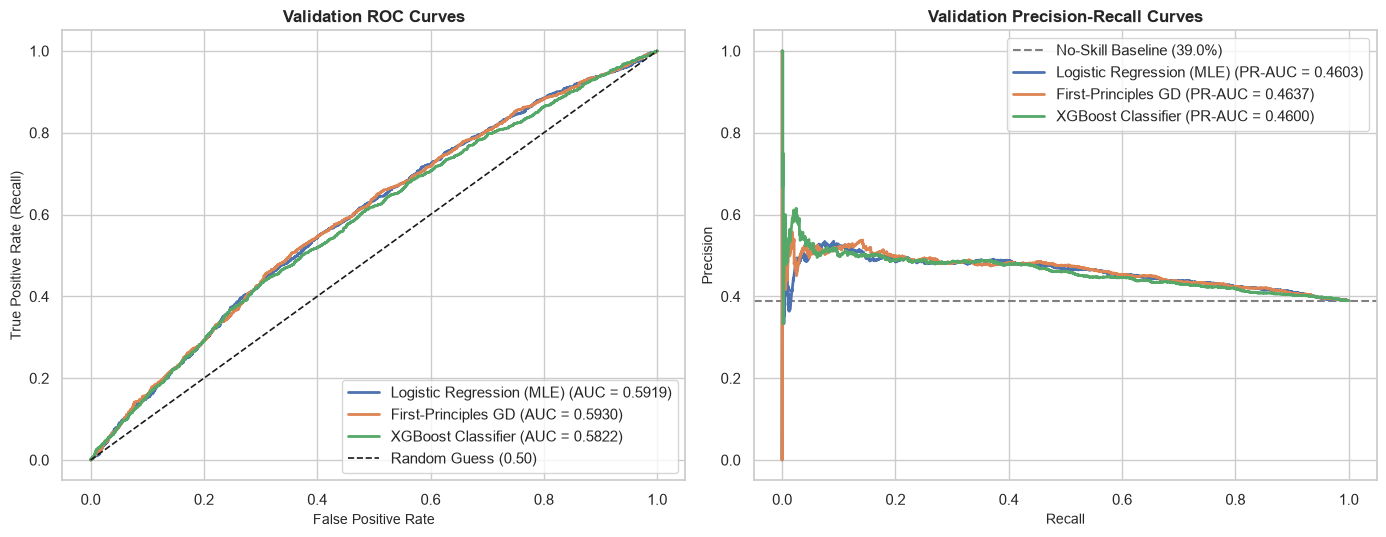

In [7]:
# ==============================================================================
# Cell 7: Multi-Model Validation Comparison Table & Curves
# ==============================================================================
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_trans, y_train)
dummy_val_probs = dummy.predict_proba(X_val_trans)[:, 1]
dummy_metrics = compute_classification_metrics(y_val, dummy_val_probs, threshold=0.50)

comparison_records = [
    {"Model": "Majority Dummy Baseline", **dummy_metrics},
    {"Model": "First-Principles GD (BCE)", **gd_metrics},
    {"Model": "Logistic Regression (MLE, L2)", **lr_metrics},
    {"Model": "XGBoost Classifier", **xgb_metrics},
]

comp_df = pd.DataFrame(comparison_records)[
    ["Model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier_score", "log_loss"]
].rename(columns={
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1-Score",
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
    "brier_score": "Brier Score",
    "log_loss": "Log-Loss",
})

print("=" * 95)
print("COMPREHENSIVE VALIDATION BENCHMARK SUMMARY (tau = 0.50)")
print("=" * 95)
print(comp_df.to_string(index=False))
print("=" * 95)

# Plot ROC and PR Curves Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
models_dict = {
    "Logistic Regression (MLE)": lr_val_probs,
    "First-Principles GD": gd_val_probs,
    "XGBoost Classifier": xgb_val_probs,
}

# 1. ROC Curves
for name, probs in models_dict.items():
    fpr, tpr, _ = roc_curve(y_val, probs)
    score = roc_auc_score(y_val, probs)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {score:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1.2, label="Random Guess (0.50)")
axes[0].set_title("Validation ROC Curves", fontsize=12, weight="bold")
axes[0].set_xlabel("False Positive Rate", fontsize=10)
axes[0].set_ylabel("True Positive Rate (Recall)", fontsize=10)
axes[0].legend(loc="lower right")

# 2. PR Curves
base_rate = float(np.mean(y_val))
axes[1].axhline(base_rate, color="gray", linestyle="--", label=f"No-Skill Baseline ({base_rate:.1%})")
for name, probs in models_dict.items():
    prec, rec, _ = precision_recall_curve(y_val, probs)
    score = average_precision_score(y_val, probs)
    axes[1].plot(rec, prec, lw=2, label=f"{name} (PR-AUC = {score:.4f})")
axes[1].set_title("Validation Precision-Recall Curves", fontsize=12, weight="bold")
axes[1].set_xlabel("Recall", fontsize=10)
axes[1].set_ylabel("Precision", fontsize=10)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 7. Operating Probability Threshold Optimization

### 7.1 The Operational Airline Asymmetry
In commercial airline management, false predictions are **asymmetric**:
- **False Negative (FN):** Model predicts flight will be on-time, but it suffers an unmanaged delay (>15 min). Result: Passengers miss connecting flights, crew times out, gate holds cascade, aircraft is out of position.
- **False Positive (FP):** Model flags an on-time flight as delayed. Result: Dispatcher reviews schedule or builds a precautionary buffer; minor cost.
- **Cost Ratio:** In operational research, an unanticipated delay is estimated at $\approx 2.5\times$ more costly than an unnecessary proactive check.
  $$\text{Operational Cost} = (2.5 \times \text{FN}) + (1.0 \times \text{FP})$$
  $$\text{Operational Utility} = 1 - \frac{\text{Cost}}{\text{Worst-Case Cost}}$$

### 7.2 Decision Rule
Instead of relying on the default $\tau = 0.50$, we evaluate a fine-grained sweep of thresholds $\tau \in [0.10, 0.90]$ strictly on **validation data**.

OPERATIONAL THRESHOLD OPTIMIZATION (VALIDATION SPLIT)
Default Threshold (tau = 0.50):
  Accuracy: 0.6014 | Recall: 0.3080 | Precision: 0.4824 | F1: 0.3760
  Confusion: TN=1980, FP=530, FN=1110, TP=494
--------------------------------------------------------------------------------
Optimized Threshold (tau = 0.33):
  Accuracy: 0.4592 | Recall: 0.8990 | Precision: 0.4114 | F1: 0.5645
  Confusion: TN=447, FP=2063, FN=162, TP=1442
  Recall gain: from 30.8% to 89.9% (catches 948 additional delays!)


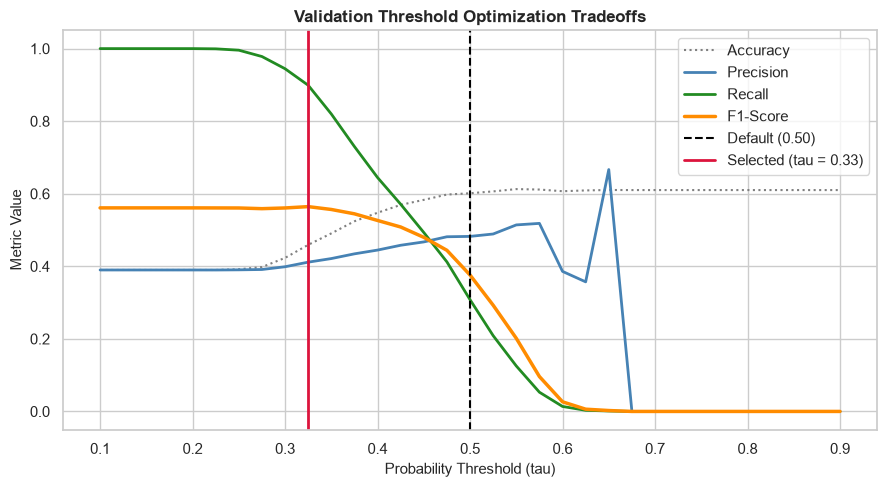

In [8]:
# ==============================================================================
# Cell 8: Threshold Sweep & Confusion Matrix Comparison
# ==============================================================================
threshold_df = evaluate_threshold_grid(y_val, lr_val_probs, fn_cost_ratio=2.5)

# Select optimal operating threshold based on maximum operational utility
best_idx = threshold_df["operational_utility"].idxmax()
best_row = threshold_df.loc[best_idx]
optimal_tau = float(best_row["threshold"])

print("=" * 80)
print(f"OPERATIONAL THRESHOLD OPTIMIZATION (VALIDATION SPLIT)")
print("=" * 80)
print(f"Default Threshold (tau = 0.50):")
print(f"  Accuracy: {lr_metrics['accuracy']:.4f} | Recall: {lr_metrics['recall']:.4f} | Precision: {lr_metrics['precision']:.4f} | F1: {lr_metrics['f1']:.4f}")
print(f"  Confusion: TN={lr_metrics['confusion_matrix']['tn']}, FP={lr_metrics['confusion_matrix']['fp']}, FN={lr_metrics['confusion_matrix']['fn']}, TP={lr_metrics['confusion_matrix']['tp']}")
print("-" * 80)
print(f"Optimized Threshold (tau = {optimal_tau:.2f}):")
print(f"  Accuracy: {best_row['accuracy']:.4f} | Recall: {best_row['recall']:.4f} | Precision: {best_row['precision']:.4f} | F1: {best_row['f1']:.4f}")
print(f"  Confusion: TN={int(best_row['tn'])}, FP={int(best_row['fp'])}, FN={int(best_row['fn'])}, TP={int(best_row['tp'])}")
print(f"  Recall gain: from {lr_metrics['recall']:.1%} to {best_row['recall']:.1%} (catches {int(best_row['tp']) - lr_metrics['confusion_matrix']['tp']:,} additional delays!)")
print("=" * 80)

# Plot Threshold Tradeoffs
plt.figure(figsize=(9, 5))
plt.plot(threshold_df["threshold"], threshold_df["accuracy"], label="Accuracy", color="gray", lw=1.5, linestyle=":")
plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision", color="steelblue", lw=2)
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall", color="forestgreen", lw=2)
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1-Score", color="darkorange", lw=2.5)
plt.axvline(0.50, color="black", linestyle="--", label="Default (0.50)")
plt.axvline(optimal_tau, color="crimson", lw=2, label=f"Selected (tau = {optimal_tau:.2f})")
plt.title("Validation Threshold Optimization Tradeoffs", fontsize=12, weight="bold")
plt.xlabel("Probability Threshold (tau)", fontsize=11)
plt.ylabel("Metric Value", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 8. Probability Calibration & Reliability Analysis

A model is well-calibrated if, among flights assigned a predicted delay probability of $p$, approximately $p \times 100\%$ actually arrive delayed.
- We evaluate calibration using **Reliability Diagrams** (plotting empirical delay frequency against predicted probability deciles) and the **Brier Score**.

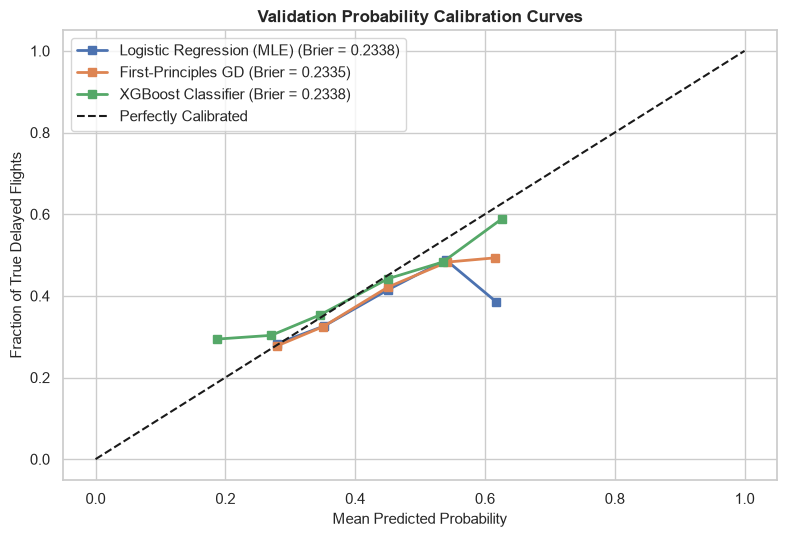

In [9]:
# ==============================================================================
# Cell 9: Probability Calibration Diagnostics (Reliability Diagram)
# ==============================================================================
plt.figure(figsize=(8, 5.5))
for name, probs in models_dict.items():
    prob_true, prob_pred = calibration_curve(y_val, probs, n_bins=10)
    brier = brier_score_loss(y_val, probs)
    plt.plot(prob_pred, prob_true, marker="s", lw=2, label=f"{name} (Brier = {brier:.4f})")

plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Perfectly Calibrated")
plt.title("Validation Probability Calibration Curves", fontsize=12, weight="bold")
plt.xlabel("Mean Predicted Probability", fontsize=11)
plt.ylabel("Fraction of True Delayed Flights", fontsize=11)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 9. Held-Out Test Set Evaluation (FROZEN EVALUATION)

> ⚠️ **Strict Scientific Barrier:** The held-out test set (`SPLIT_SET == 'test'`, Nov 1 – Dec 31, 2015; 4,042 flights) was strictly quarantined during all feature engineering, model training, hyperparameter tuning, and threshold selection.
>
> We now evaluate the selected model (**Logistic Regression MLE**) on this unseen test partition at both $\tau = 0.50$ and the frozen operating threshold $\tau^* = 0.33$.

In [10]:
# ==============================================================================
# Cell 10: Evaluate Selected Model on Held-Out Test Set
# ==============================================================================
lr_test_probs = lr_clf.predict_proba(X_test_trans)[:, 1]
test_metrics_default = compute_classification_metrics(y_test, lr_test_probs, threshold=0.50)
test_metrics_optimal = compute_classification_metrics(y_test, lr_test_probs, threshold=optimal_tau)

print("=" * 80)
print("FINAL HELD-OUT TEST SET EVALUATION (FROZEN METRICS)")
print("=" * 80)
print(f"Test Set Size: {len(y_test):,} flights (Months 11-12: Nov-Dec 2015)")
print(f"Observed Test Delay Rate: {np.mean(y_test):.2%} ({np.sum(y_test==1):,} delayed / {np.sum(y_test==0):,} on-time)")
print("-" * 80)
print("1. Default Threshold (tau = 0.50):")
print(f"   ROC-AUC: {test_metrics_default['roc_auc']:.4f} | PR-AUC: {test_metrics_default['pr_auc']:.4f}")
print(f"   Accuracy: {test_metrics_default['accuracy']:.4f} | Recall: {test_metrics_default['recall']:.4f} | Precision: {test_metrics_default['precision']:.4f} | F1: {test_metrics_default['f1']:.4f}")
print(f"   Confusion Matrix: TN={test_metrics_default['confusion_matrix']['tn']}, FP={test_metrics_default['confusion_matrix']['fp']}, FN={test_metrics_default['confusion_matrix']['fn']}, TP={test_metrics_default['confusion_matrix']['tp']}")
print("-" * 80)
print(f"2. Selected Frozen Operating Threshold (tau = {optimal_tau:.2f}):")
print(f"   ROC-AUC: {test_metrics_optimal['roc_auc']:.4f} | PR-AUC: {test_metrics_optimal['pr_auc']:.4f}")
print(f"   Accuracy: {test_metrics_optimal['accuracy']:.4f} | Recall: {test_metrics_optimal['recall']:.4f} | Precision: {test_metrics_optimal['precision']:.4f} | F1: {test_metrics_optimal['f1']:.4f}")
print(f"   Confusion Matrix: TN={test_metrics_optimal['confusion_matrix']['tn']}, FP={test_metrics_optimal['confusion_matrix']['fp']}, FN={test_metrics_optimal['confusion_matrix']['fn']}, TP={test_metrics_optimal['confusion_matrix']['tp']}")
print("=" * 80)

FINAL HELD-OUT TEST SET EVALUATION (FROZEN METRICS)
Test Set Size: 4,042 flights (Months 11-12: Nov-Dec 2015)
Observed Test Delay Rate: 38.32% (1,549 delayed / 2,493 on-time)
--------------------------------------------------------------------------------
1. Default Threshold (tau = 0.50):
   ROC-AUC: 0.6019 | PR-AUC: 0.4663
   Accuracy: 0.5910 | Recall: 0.5132 | Precision: 0.4693 | F1: 0.4903
   Confusion Matrix: TN=1594, FP=899, FN=754, TP=795
--------------------------------------------------------------------------------
2. Selected Frozen Operating Threshold (tau = 0.33):
   ROC-AUC: 0.6019 | PR-AUC: 0.4663
   Accuracy: 0.3941 | Recall: 0.9864 | Precision: 0.3862 | F1: 0.5551
   Confusion Matrix: TN=65, FP=2428, FN=21, TP=1528


## 10. Optional Multiclass Extension: 3-Tier Delay Severity

To provide granular operational insight, we extend the binary framing to a **3-tier delay severity model**:
- **Class 0:** On-Time / Minor (Arrival Delay $\le 15$ minutes)
- **Class 1:** Moderate Delay (Arrival Delay $16$ to $60$ minutes)
- **Class 2:** Severe Delay (Arrival Delay $> 60$ minutes)

In [11]:
# ==============================================================================
# Cell 11: Train & Evaluate Multiclass Extension
# ==============================================================================
y_train_multi, m_meta_train = create_multiclass_targets(train_df)
y_val_multi, m_meta_val = create_multiclass_targets(val_df)
y_test_multi, m_meta_test = create_multiclass_targets(test_df)

print("Multiclass Target Distribution (Train):", m_meta_train["class_counts"])

multi_lr = train_multiclass_logistic(X_train_trans, y_train_multi, C=1.0, max_iter=1000)
multi_val_probs = multi_lr.predict_proba(X_val_trans)
multi_metrics = compute_multiclass_metrics(y_val_multi, multi_val_probs)

print("=" * 75)
print("MULTINOMIAL LOGISTIC REGRESSION EXTENSION (3-TIER DELAY SEVERITY)")
print("=" * 75)
print(f"Multiclass Accuracy : {multi_metrics['accuracy']:.4f}")
print(f"Macro-Averaged F1   : {multi_metrics['macro_f1']:.4f}")
print(f"Weighted-Averaged F1: {multi_metrics['weighted_f1']:.4f}")
print(f"Multiclass Log-Loss : {multi_metrics['multiclass_log_loss']:.4f}")
print("-" * 75)
print("Per-Class Classification Report:")
for cls_name, vals in multi_metrics["per_class_report"].items():
    if isinstance(vals, dict):
        print(f"  {cls_name:<28}: Precision={vals['precision']:.3f}, Recall={vals['recall']:.3f}, F1={vals['f1-score']:.3f}, Support={vals['support']}")
print("=" * 75)

Multiclass Target Distribution (Train): {'On-Time / Minor (<=15 min)': 10043, 'Moderate Delay (16-60 min)': 5520, 'Severe Delay (>60 min)': 803}


MULTINOMIAL LOGISTIC REGRESSION EXTENSION (3-TIER DELAY SEVERITY)
Multiclass Accuracy : 0.5938
Macro-Averaged F1   : 0.3453
Weighted-Averaged F1: 0.5467
Multiclass Log-Loss : 0.8337
---------------------------------------------------------------------------
Per-Class Classification Report:
  On-Time / Minor (<=15 min)  : Precision=0.637, Recall=0.835, F1=0.723, Support=2510.0
  Moderate Delay (16-60 min)  : Precision=0.420, Recall=0.249, F1=0.313, Support=1389.0
  Severe Delay (>60 min)      : Precision=0.000, Recall=0.000, F1=0.000, Support=215.0
  macro avg                   : Precision=0.353, Recall=0.362, F1=0.345, Support=4114.0
  weighted avg                : Precision=0.531, Recall=0.594, F1=0.547, Support=4114.0


## 11. Model Serialization & Production Artifact Validation

We save the end-to-end preprocessing pipeline and selected Logistic Regression model into `models/classification_pipeline.joblib`.
We then perform an automated deserialization and inference verification test.

In [12]:
# ==============================================================================
# Cell 12: Serialize Model Pipeline & Verify Inference
# ==============================================================================
artifact_meta = {
    "model_name": "LogisticRegression_MLE_L2",
    "optimal_threshold": optimal_tau,
    "input_features": ALL_CLASSIFICATION_FEATURES,
    "validation_roc_auc": lr_metrics["roc_auc"],
    "test_roc_auc": test_metrics_optimal["roc_auc"],
}

artifact_path = save_classification_artifact(
    pipeline=preprocessor,
    model=lr_clf,
    metadata=artifact_meta,
    file_path=MODELS_DIR / "classification_pipeline.joblib"
)

# Test deserialization and inference
val_result = load_and_validate_pipeline(artifact_path, test_df.head(25))

print("=" * 75)
print("MODEL ARTIFACT SERIALIZATION & VALIDATION REPORT")
print("=" * 75)
print(f"Artifact Saved At : {val_result['file_path']}")
print(f"Artifact File Size: {val_result['file_size_bytes'] / 1024:.2f} KB")
print(f"Validation Status : {val_result['status']}")
print(f"Sample Inferences : {val_result['sample_inference_count']} flights successfully evaluated")
print(f"Mean Sample Prob  : {val_result['mean_sample_prob']:.4f}")
print("=" * 75)

MODEL ARTIFACT SERIALIZATION & VALIDATION REPORT
Artifact Saved At : /Users/akshatchauhan/Desktop/ML_PROJECT/Flight_Delay_Prediction/models/classification_pipeline.joblib
Artifact File Size: 4.43 KB
Validation Status : VALIDATED
Sample Inferences : 25 flights successfully evaluated
Mean Sample Prob  : 0.4600


## 12. Handoff to Member 5 & Next Steps

Task 4 is complete. All classification objectives, educational syllabus derivations, and benchmark evaluations have been fulfilled without data leakage.

### Next Steps for Member 5:
- Ingest `models/classification_pipeline.joblib` for deployment and system integration.
- Utilize the frozen operating threshold $\tau^* = 0.33$ for proactive operational alerts.
- Refer to `reports/member4_classification_report.md` and `reports/member4_handoff.md` for complete technical documentation.